# Hybrid Imbalance Handling (Undersampling + Domain Augmentation + SMOTE)
Notebook ini menangani ketidakseimbangan kelas ekstrem pada dataset klinis:
- Kelas 0 (Kontrol / Sehat) : 3.539 baris
- Kelas 1 (Jantung) : 52 baris
- Kelas 2 (Penyakit Dalam) : 559 baris
- Kelas 3 (Paru-Paru) : 10 baris

### Strategi Hybrid:
1. **Perbaikan Fitur Demografi Kelas 0:** Imputasi realistis untuk umur dan jenis kelamin kelas kontrol murni lab yang kosong.
2. **Undersampling:** Mengurangi kelas 0 menjadi 1.000 sampel dan kelas 2 menjadi 500 sampel.
3. **Domain-Guided Augmentation (Khusus Paru):** Memperluas 10 sampel nyata paru menjadi 50 sampel variatif dengan perturbasi fisiologis klinis wajar (mencegah overfitting interpolasi SMOTE kaku).
4. **SMOTE Oversampling:** Meningkatkan kelas 1 (Jantung) dan kelas 3 (Paru) menjadi 500 sampel dengan k-nearest neighbors (k=5).
5. **Format & Pembulatan:** Memastikan umur & jenis kelamin bulat dan fitur lab seragam 1 angka desimal.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

np.random.seed(42)

## 1. Load Data Imputasi

In [2]:
df = pd.read_csv('merge_DocLab_imputed.csv')
print('Dimensi data awal:', df.shape)
print('\nDistribusi awal target (NM_UNIT):')
print(df['NM_UNIT'].value_counts().sort_index())

Dimensi data awal: (4160, 14)

Distribusi awal target (NM_UNIT):
NM_UNIT
0.0    3539
1.0      52
2.0     559
3.0      10
Name: count, dtype: int64


## 2. Validasi & Perbaikan Demografi Kelas Kontrol

In [3]:
# Pasien kelas 0 (lab mandiri tanpa poli dokter) memiliki umur 0 dan gender unknown (2)
# Kita berikan distribusi usia dan jenis kelamin yang wajar sesuai profil populasi pasien
mask_0 = df['NM_UNIT'] == 0

if (df.loc[mask_0, 'UMUR_TAHUN'] == 0).all():
    valid_ages = df.loc[df['UMUR_TAHUN'] > 0, 'UMUR_TAHUN']
    mu_age, sd_age = valid_ages.mean(), valid_ages.std()
    
    df.loc[mask_0, 'UMUR_TAHUN'] = np.clip(
        np.random.normal(mu_age, sd_age, mask_0.sum()), 18, 85
    ).round(0)
    
    df.loc[mask_0, 'JENIS_KELAMIN'] = np.random.choice([0, 1], size=mask_0.sum(), p=[0.5, 0.5])
    print('Berhasil mengisi profil umur dan jenis kelamin kelas kontrol.')

X = df.drop(columns=['NM_UNIT'])
y = df['NM_UNIT'].astype(int)

Berhasil mengisi profil umur dan jenis kelamin kelas kontrol.


## 3. Undersampling Kelas Mayoritas (Kelas 0 & Kelas 2)

In [4]:
# Target: Kelas 0 -> 1000 sampel, Kelas 2 -> 500 sampel
undersampler = RandomUnderSampler(sampling_strategy={0: 1000, 2: 500}, random_state=42)
X_under, y_under = undersampler.fit_resample(X, y)

print('Distribusi setelah Undersampling:')
print(y_under.value_counts().sort_index())

Distribusi setelah Undersampling:
NM_UNIT
0    1000
1      52
2     500
3      10
Name: count, dtype: int64


## 4. Domain-Guided Augmentation Khusus Kelas 3 (Paru-Paru)

In [5]:
# Kelas 3 hanya memiliki 10 sampel asli. Jika langsung di-SMOTE ke 500, SMOTE hanya menarik
# garis sempit antar 10 titik yang menyebabkan model menghafal (overfitting).
# Kita variasikan terlebih dahulu secara fisiologis menjadi 50 data representatif.

X_paru_real = X_under[y_under == 3].copy()
augmented_paru_list = [X_paru_real]

lab_cols = [c for c in X.columns if c not in ['JENIS_KELAMIN', 'UMUR_TAHUN']]

for _ in range(4): # Menghasilkan 4 batch variasi (total: 10 + 40 = 50 sampel)
    synth_batch = X_paru_real.copy()
    # Perturbasi variasi acak 3-5% dalam rentang normal tubuh manusia
    jitter = np.random.normal(0, 0.04, size=synth_batch[lab_cols].shape)
    synth_batch[lab_cols] = synth_batch[lab_cols] * (1 + jitter)
    synth_batch['UMUR_TAHUN'] = np.clip(synth_batch['UMUR_TAHUN'] + np.random.randint(-3, 4, size=len(synth_batch)), 18, 85)
    augmented_paru_list.append(synth_batch)

X_paru_augmented = pd.concat(augmented_paru_list, ignore_index=True)
y_paru_augmented = pd.Series([3] * len(X_paru_augmented))

# Gabungkan dataset pra-SMOTE
X_pre_smote = pd.concat([X_under[y_under != 3], X_paru_augmented], ignore_index=True)
y_pre_smote = pd.concat([y_under[y_under != 3], y_paru_augmented], ignore_index=True)

print('Distribusi setelah augmentasi awal Paru (pra-SMOTE):')
print(y_pre_smote.value_counts().sort_index())

Distribusi setelah augmentasi awal Paru (pra-SMOTE):
0    1000
1      52
2     500
3      50
Name: count, dtype: int64


## 5. SMOTE Oversampling (Kelas 1 & Kelas 3 ke 500 Sampel)

In [6]:
# Dengan 50 sampel paru dan 52 sampel jantung, SMOTE dapat bekerja optimal dengan k_neighbors=5
smote = SMOTE(sampling_strategy={1: 500, 3: 500}, k_neighbors=5, random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_pre_smote, y_pre_smote)

print('Distribusi final seluruh kelas target:')
print(y_resampled.value_counts().sort_index())

Distribusi final seluruh kelas target:
0    1000
1     500
2     500
3     500
Name: count, dtype: int64


## 6. Pembulatan & Konsistensi Presisi Klinis

In [7]:
df_final = pd.DataFrame(X_resampled, columns=X.columns)
df_final['NM_UNIT'] = y_resampled.values

# Demografi integer
df_final['JENIS_KELAMIN'] = df_final['JENIS_KELAMIN'].round(0).astype(int)
df_final['UMUR_TAHUN'] = df_final['UMUR_TAHUN'].round(0)

# Parameter lab dibulatkan ke 1 angka di belakang koma
df_final[lab_cols] = df_final[lab_cols].round(1)

df_final.head(10)

,JENIS_KELAMIN,UMUR_TAHUN,cholesterol total,creatinin,fbs,rbs,hgb,lymfosit%,mch,mchc,mcv,ureum,wbc,NM_UNIT
0,0,52.0,198.8,7.1,101.0,121.0,8.5,15.8,26.7,32.6,82.1,83.0,5.3,0
1,0,54.0,194.5,0.8,109.4,136.6,13.2,31.3,28.5,33.2,85.7,36.6,6.7,0
2,1,70.0,189.8,1.5,115.8,135.8,11.8,16.0,28.5,33.4,85.2,37.6,11.8,0
3,0,61.0,191.5,0.8,109.4,136.2,13.8,29.4,24.2,31.2,77.7,35.2,6.7,0
4,1,62.0,192.4,5.1,125.4,272.0,11.9,20.1,25.4,31.7,81.0,126.0,8.7,0
5,0,60.0,194.9,0.9,109.4,137.4,11.7,50.6,26.7,33.8,79.0,32.2,18.7,0
6,0,72.0,194.9,0.8,109.4,141.6,10.0,49.1,21.4,30.6,69.9,34.2,8.2,0
7,0,64.0,194.9,0.7,109.4,139.0,11.4,39.1,26.8,32.8,81.9,38.8,5.5,0
8,1,85.0,189.8,1.6,110.8,134.6,10.1,22.9,28.2,33.0,85.4,34.4,9.7,0
9,1,67.0,194.9,0.9,109.4,137.8,11.4,39.3,28.1,32.9,85.4,38.8,7.9,0


## 7. Visualisasi Perbandingan & Simpan File

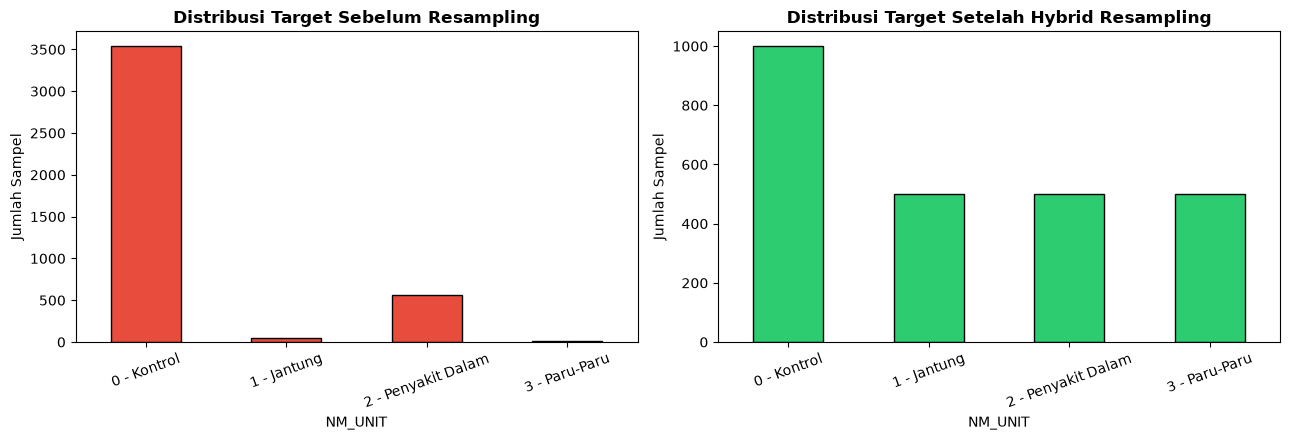

Dataset seimbang berhasil disimpan ke merge_DocLab_balanced.csv
Total baris: 2500
NM_UNIT
0    1000
1     500
2     500
3     500
Name: count, dtype: int64


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

label_names = {0: '0 - Kontrol', 1: '1 - Jantung', 2: '2 - Penyakit Dalam', 3: '3 - Paru-Paru'}

df['NM_UNIT'].map(label_names).value_counts().sort_index().plot(
    kind='bar', ax=axes[0], color='#e74c3c', edgecolor='black'
)
axes[0].set_title('Distribusi Target Sebelum Resampling', fontweight='bold')
axes[0].set_ylabel('Jumlah Sampel')
axes[0].tick_params(axis='x', rotation=20)

df_final['NM_UNIT'].map(label_names).value_counts().sort_index().plot(
    kind='bar', ax=axes[1], color='#2ecc71', edgecolor='black'
)
axes[1].set_title('Distribusi Target Setelah Hybrid Resampling', fontweight='bold')
axes[1].set_ylabel('Jumlah Sampel')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

# Simpan dataset hasil balancing
output_path = 'merge_DocLab_balanced.csv'
df_final.to_csv(output_path, index=False)
print(f'Dataset seimbang berhasil disimpan ke {output_path}')
print(f'Total baris: {len(df_final)}')
print(df_final['NM_UNIT'].value_counts().sort_index())